In [57]:
#Importing necessities
import lightkurve as lk
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np
import pandas as pd
from astropy.timeseries import LombScargle

%matplotlib inline

In [58]:
#Important functions
def getOOE(dataframe, jump_threshold):
    ''' identifies the out-of-eclipse (OOE) data points in a light curve'''
    
    Npts = len(dataframe)
    # Compute the median of the entire light curve (including eclipses/flares).
    median_raw = np.nanmedian(dataframe["flux"])
    
    # Compute a running median every 3 points.
    medians = np.zeros(Npts)
    for i in range(Npts):
        if i < Npts-2:
            medians[i] = np.nanmedian(dataframe["flux"].iloc[[i,i+1,i+2]])
        elif i == Npts-2:
            medians[i] = np.nanmedian(dataframe["flux"].iloc[[i,i+1]])
        else:
            medians[i] = dataframe["flux"].iloc[i]
    
    # Check for points where the median changes by too much.
    bool_keep = np.zeros(Npts) + 1  # setting them all to True to start
    for i in range(Npts-1):
        if abs(medians[i]-medians[i+1]) > jump_threshold or abs(medians[i]-median_raw) > 100:
            bool_keep[i:i+3] = 0
            bool_keep[i-3:i] = 0
    indx_OOE = np.where(bool_keep)[0]
    
    return(indx_OOE)

In [59]:
#get archival data for Freya (TIC 0172517058)
search_result = lk.search_lightcurve("TIC 0172517058") #Freya
print(search_result)
indx_lc = np.where(search_result.table["author"] == "TESS-SPOC")[0] 
lc_many = search_result[indx_lc].download_all()
data0_raw, data1_raw, data2_raw, data3_raw, data4_raw, data5_raw = lc_many[0].to_pandas(), lc_many[1].to_pandas(), lc_many[2].to_pandas(), lc_many[3].to_pandas(), lc_many[4].to_pandas(), lc_many[5].to_pandas() 

#   Sector 21
indx_ok = np.where(np.isfinite(data0_raw["flux"]))[0]
data0 = data0_raw.filter(items=data0_raw.index[indx_ok], axis=0)
data0.index = (((data0.index + 2457000) -2451545.25) /356.25) + 2000 #in years
#   Sector 46
indx_ok = np.where(np.isfinite(data1_raw["flux"]))[0]
data1 = data1_raw.filter(items=data1_raw.index[indx_ok], axis=0)
data1.index = (((data1.index + 2457000) -2451545.25) /356.25) + 2000 #in years
#   Sector 45
indx_ok = np.where(np.isfinite(data2_raw["flux"]))[0]
data2 = data2_raw.filter(items=data2_raw.index[indx_ok], axis=0)
data2.index = (((data2.index + 2457000) -2451545.25) /356.25) + 2000 #in years
#    Sector 44
indx_ok = np.where(np.isfinite(data3_raw["flux"]))[0]
data3 = data3_raw.filter(items=data3_raw.index[indx_ok], axis=0)
data3.index = (((data3.index + 2457000) -2451545.25) /356.25) + 2000 #in years
#   Sector 48
indx_ok = np.where(np.isfinite(data4_raw["flux"]))[0]
data4 = data4_raw.filter(items=data4_raw.index[indx_ok], axis=0)
data4.index = (((data4.index + 2457000) -2451545.25) /356.25) + 2000 #in years
#   Sector 2023
indx_ok = np.where(np.isfinite(data5_raw["flux"]))[0]
data5 = data5_raw.filter(items=data5_raw.index[indx_ok], axis=0)
data5.index = (((data5.index + 2457000) -2451545.25) /356.25) + 2000 #in years
#   Some points...
Npts0, Npts1, Npts2, Npts3, Npts4, Npts5 = len(data0), len(data1), len(data2), len(data3), len(data4), len(data5)


SearchResult containing 25 data products.

 #      mission      year   author  exptime target_name distance
                                       s                 arcsec 
--- ---------------- ---- --------- ------- ----------- --------
  0   TESS Sector 21 2020      SPOC     120   172517058      0.0
  1   TESS Sector 44 2021      SPOC     120   172517058      0.0
  2   TESS Sector 45 2021      SPOC     120   172517058      0.0
  3   TESS Sector 46 2021      SPOC     120   172517058      0.0
  4   TESS Sector 48 2022      SPOC     120   172517058      0.0
  5   TESS Sector 72 2023      SPOC     120   172517058      0.0
  6   TESS Sector 21 2020 TESS-SPOC    1800   172517058      0.0
  7   TESS Sector 44 2021 TESS-SPOC     600   172517058      0.0
  8   TESS Sector 45 2021 TESS-SPOC     600   172517058      0.0
  9   TESS Sector 46 2021 TESS-SPOC     600   172517058      0.0
 10   TESS Sector 48 2022 TESS-SPOC     600   172517058      0.0
 11   TESS Sector 72 2023 TESS-SPOC     200   1

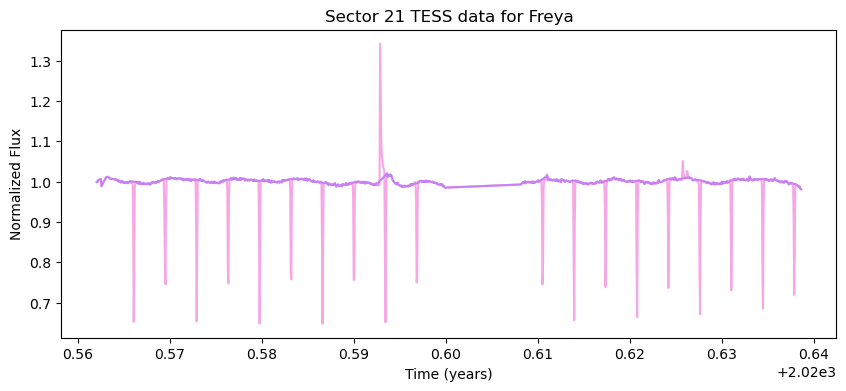

In [60]:
#first section 
indx_outofeclipse0 = getOOE(data0, 20)
    #Median flux but only for the OOE points
median0 =  np.median(data0['flux'].iloc[indx_outofeclipse0])  
median0_err = np.median(data0['flux_err'].iloc[indx_outofeclipse0])
    #Making the df 
data0_normed = data0[["flux", "flux_err"]].copy() 
    #Normalising flux and error propagation  
data0_normed["flux"] = data0['flux']/median0
data0_normed["flux_err"] = data0['flux_err']/median0_err
    #plotting
fig, ax = plt.subplots(1,1, figsize=(10,4)) 
ax.plot(data0_normed.index, data0_normed["flux"], c="#f7a7e5")
ax.plot(data0_normed.index[indx_outofeclipse0], data0_normed['flux'].iloc[indx_outofeclipse0], c="#c682f4")
plt.ylabel("Normalized Flux")
plt.xlabel("Time (years)")
plt.title("Sector 21 TESS data for Freya")
plt.show()

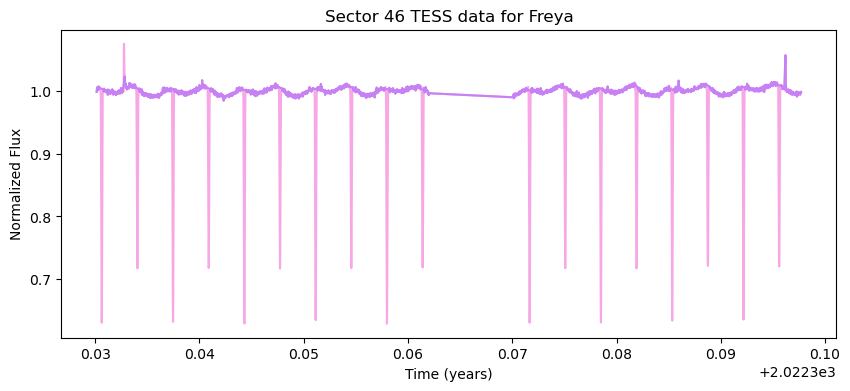

In [61]:
#Second Sector
fig, ax = plt.subplots(1,1, figsize=(10,4))  # initializing the plot!

indx_outofeclipse1 = getOOE(data1, 22)
median1 = np.median(data1['flux'].iloc[indx_outofeclipse1])  
median1_err = np.median(data1['flux_err'].iloc[indx_outofeclipse1])
data1_normed = data1[["flux", "flux_err"]].copy()
data1_normed["flux"] = data1['flux']/median1
data1_normed["flux_err"] = data1['flux_err']/median1_err

ax.plot(data1_normed.index, data1_normed["flux"], c="#f7a7e5")
ax.plot(data1_normed.index[indx_outofeclipse1], data1_normed['flux'].iloc[indx_outofeclipse1], c="#c682f4")
plt.ylabel("Normalized Flux")
plt.xlabel("Time (years)")
ax.set_title("Sector 46 TESS data for Freya")
plt.show()

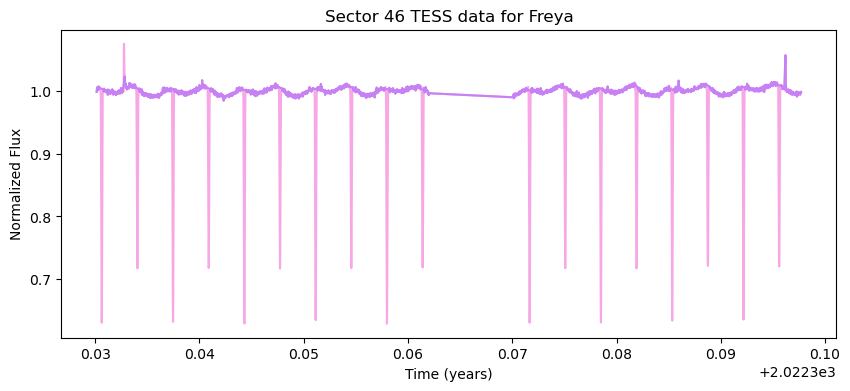

In [62]:
#Second Sector
fig, ax = plt.subplots(1,1, figsize=(10,4))  # initializing the plot!

indx_outofeclipse1 = getOOE(data1, 22)
median1 = np.median(data1['flux'].iloc[indx_outofeclipse1])  
median1_err = np.median(data1['flux_err'].iloc[indx_outofeclipse1])
data1_normed = data1[["flux", "flux_err"]].copy()
data1_normed["flux"] = data1['flux']/median1
data1_normed["flux_err"] = data1['flux_err']/median1_err

ax.plot(data1_normed.index, data1_normed["flux"], c="#f7a7e5")
ax.plot(data1_normed.index[indx_outofeclipse1], data1_normed['flux'].iloc[indx_outofeclipse1], c="#c682f4")
plt.ylabel("Normalized Flux")
plt.xlabel("Time (years)")
ax.set_title("Sector 46 TESS data for Freya")
plt.show()

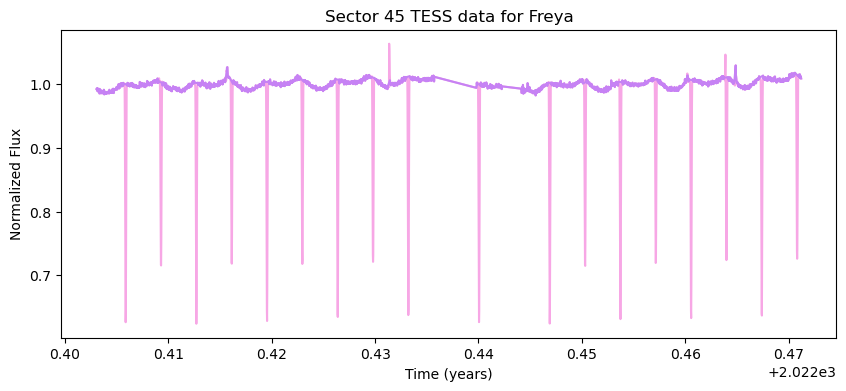

In [63]:
#third sector
fig, ax = plt.subplots(1,1, figsize=(10,4)) 

indx_outofeclipse2 = getOOE(data2, 22)
median2 = np.median(data2['flux'].iloc[indx_outofeclipse2])  
median2_err = np.median(data2['flux_err'].iloc[indx_outofeclipse2])
data2_normed = data2[["flux", "flux_err"]].copy()
data2_normed["flux"] = data2['flux']/median2
data2_normed["flux_err"] = data2['flux_err']/median2_err

# Plot.
ax.plot(data2_normed.index, data2_normed["flux"], c="#f7a7e5")
ax.plot(data2_normed.index[indx_outofeclipse2], data2_normed['flux'].iloc[indx_outofeclipse2], c="#c682f4")
plt.ylabel("Normalized Flux")
plt.xlabel("Time (years)")
ax.set_title("Sector 45 TESS data for Freya")
plt.show()

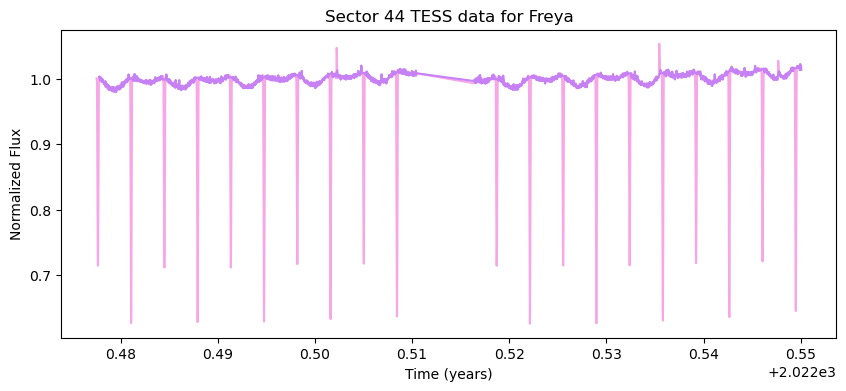

In [64]:
#forth sector
indx_outofeclipse3 = getOOE(data3, 20) 

median3 =  np.median(data3['flux'].iloc[indx_outofeclipse3]) 
median3_err = np.median(data3['flux_err'].iloc[indx_outofeclipse3])
data3_normed = data3[["flux", "flux_err"]].copy()
data3_normed["flux"] = data3['flux']/median3
data3_normed["flux_err"] = data3['flux_err']/median3_err

fig, ax = plt.subplots(1,1, figsize=(10,4))
ax.plot(data3_normed.index, data3_normed["flux"], c="#f7a7e5")
ax.plot(data3_normed.index[indx_outofeclipse3], data3_normed['flux'].iloc[indx_outofeclipse3], c="#c682f4")
plt.ylabel("Normalized Flux")
plt.xlabel("Time (years)")
ax.set_title("Sector 44 TESS data for Freya")
plt.show()

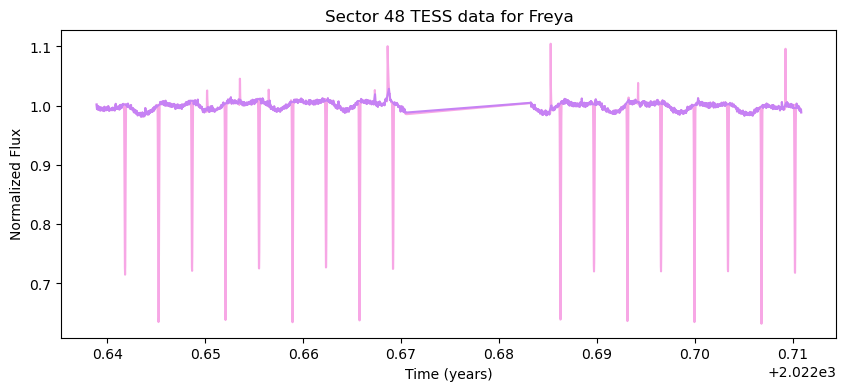

In [65]:
#fifth sector
indx_outofeclipse4 = getOOE(data4, 20) # call getOOE() here!

median4 =  np.median(data4['flux'].iloc[indx_outofeclipse4]) 
median4_err = np.median(data4['flux_err'].iloc[indx_outofeclipse4])
data4_normed = data4[["flux", "flux_err"]].copy()  
data4_normed["flux"] = data4['flux']/median4
data4_normed["flux_err"] = data4['flux_err']/median4_err

fig, ax = plt.subplots(1,1, figsize=(10,4))
ax.plot(data4_normed.index, data4_normed["flux"], c="#f7a7e5")
ax.plot(data4_normed.index[indx_outofeclipse4], data4_normed['flux'].iloc[indx_outofeclipse4], c="#c682f4")
plt.ylabel("Normalized Flux")
plt.xlabel("Time (years)")
ax.set_title("Sector 48 TESS data for Freya")
plt.show()

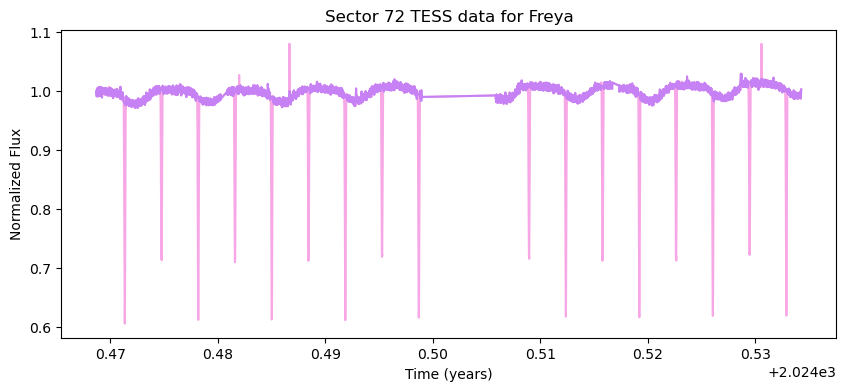

In [66]:
indx_outofeclipse5 = getOOE(data5, 20) # call getOOE() here!

median5 =  np.median(data5['flux'].iloc[indx_outofeclipse5]) 
median5_err = np.median(data5['flux_err'].iloc[indx_outofeclipse5])
data5_normed = data5[["flux", "flux_err"]].copy()  
data5_normed["flux"] = data5['flux']/median5
data5_normed["flux_err"] = data5['flux_err']/median5_err

fig, ax = plt.subplots(1,1, figsize=(10,4))
ax.plot(data5_normed.index, data5_normed["flux"], c="#f7a7e5")
ax.plot(data5_normed.index[indx_outofeclipse5], data5_normed['flux'].iloc[indx_outofeclipse5], c="#c682f4")
plt.ylabel("Normalized Flux")
plt.xlabel("Time (years)")
ax.set_title("Sector 72 TESS data for Freya")
plt.show()

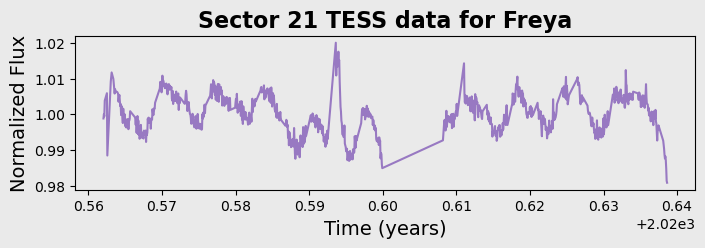

In [67]:
fig, ax = plt.subplots(1,1, figsize=(8,2)) 
ax.plot(data0_normed.index[indx_outofeclipse0], data0_normed['flux'].iloc[indx_outofeclipse0], c="#9879C2")
plt.ylabel("Normalized Flux", fontsize='14')
plt.xlabel("Time (years)", fontsize='14')
plt.title("Sector 21 TESS data for Freya", fontsize='16', fontweight='bold')
fig.set_facecolor('#EAEAEA')
ax.set_facecolor('#EAEAEA')
plt.show()

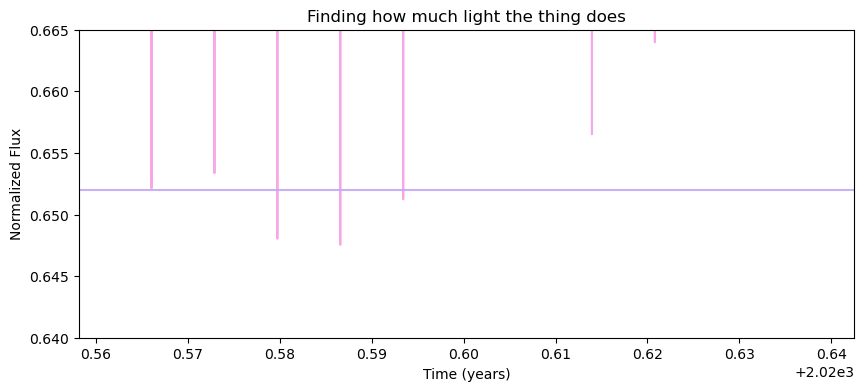

In [68]:
#Measuring flux ratio
depth = 0.652
fig, ax = plt.subplots(1,1, figsize=(10,4)) 
ax.plot(data0_normed.index, data0_normed["flux"], c="#f7a7e5")
ax.axhline(y=depth, color="#c3a7f7", linestyle='-', label=f'secondary', alpha=0.9)
plt.ylabel("Normalized Flux")
plt.xlabel("Time (years)")
plt.title("Finding how much light the thing does")
ax.set_ylim(0.64, 0.665)
plt.show()

In [69]:
primary = depth
print(f"Depth = {primary}")
secondary = (1-depth)
print(f"we lose {(1-depth)*100:.3}% of the light when secondary star is blocked")
print(f"The primary start contributes {primary*100:.3}% of the light")
print(f"The secondary star contributes {secondary*100:.3}% of the light")

Depth = 0.652
we lose 34.8% of the light when secondary star is blocked
The primary start contributes 65.2% of the light
The secondary star contributes 34.8% of the light


In [70]:
#Putting all of the points together 
    #making all of the fluxes in one df
data_all = pd.concat([data0_normed.iloc[indx_outofeclipse0], data1_normed.iloc[indx_outofeclipse1], data2_normed.iloc[indx_outofeclipse2], data3_normed.iloc[indx_outofeclipse3], data4_normed.iloc[indx_outofeclipse4], data5_normed.iloc[indx_outofeclipse5]]) #, dataP.iloc[indx_outofeclipseP]])
print(f"length: {len(data_all)}")

length: 20418


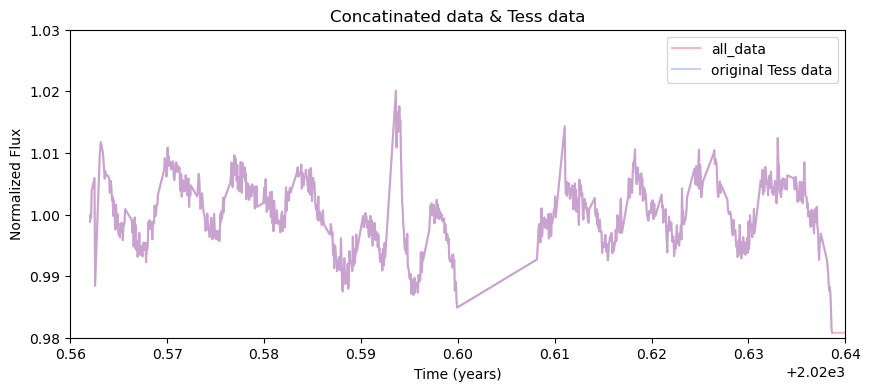

In [71]:
#Checking that the combined data matches the original indivdual TESS sectors
fig, ax = plt.subplots(1,1, figsize=(10,4))
ax.plot(data_all.index, data_all['flux'], c="#f7a7a8", alpha=0.8, label = 'all_data')
ax.plot(data0_normed.index[indx_outofeclipse0], data0_normed['flux'].iloc[indx_outofeclipse0], c="#8284f4", alpha=0.4, label='original Tess data')

plt.ylabel("Normalized Flux")
plt.xlabel("Time (years)")
ax.set_title("Concatinated data & Tess data")
ax.set_ylim(0.98, 1.03)
ax.set_xlim(2020.56, 2020.64)
plt.legend(loc='best')
plt.show()

[2.50998996 2.48508917 2.49126793]
  Top 3 periods (in days) =  2.5099899598393574 2.4850891667826396 2.4912679312595607
  (their powers were:  [0.37417326 0.34873741 0.30447006]


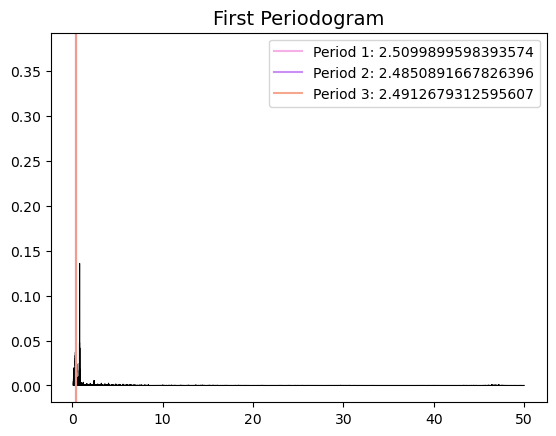

In [72]:
#Creating the first periodogram
possiblef = np.linspace(0.1, 50, 50000) #possible frequencies
power = LombScargle(data_all.index.values*365.25,data_all['flux'].values).power(possiblef)
frequency = possiblef
period = 1 / frequency

indx_sorted = (-power).argsort()
print(period[indx_sorted[0:3]])
p1, p2, p3 = period[indx_sorted[0:3]] #period but in days??
print("  Top 3 periods (in days) = ",p1, p2, p3) 
print("  (their powers were: ",power[indx_sorted[0:3]])

fig, ax = plt.subplots()
ax.plot(frequency, power, c='black', linewidth = '0.8')
ax.axvline(x=1/p1, color='#f7a7e5', linestyle='-', label=f'Period 1: {p1}', alpha=0.9)
ax.axvline(x=1/p2, color='#c682f4', linestyle='-', label=f'Period 2: {p2}', alpha=0.9)
ax.axvline(x=1/p3, color="#f49f82", linestyle='-', label=f'Period 3: {p3}', alpha=0.9)
ax.set_title('First Periodogram', fontsize=14)
#ax.set_xlim(0.5,8) #goes to 25, but it's a flat line so I'm zooming in!
ax.legend()
plt.show()

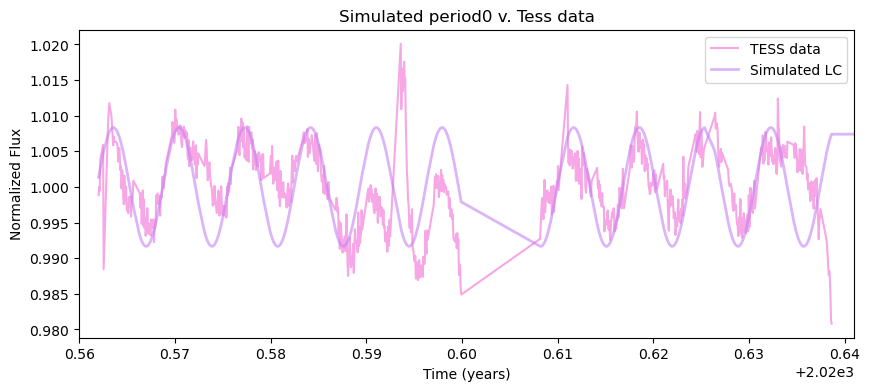

In [73]:
#Plotting a simulated LC
x_vals = data_all.index
    #choosing the best period 
period0 = p1 /365.25

#creating a sin function for the simulated LC
    #amplitude...
amp0 = 1 / 120 #to get the sin function between 1.02 and 0.98?
    #omega
omega0 = (2 * np.pi) / period0 
    #vertical shift
vShift0 = 1
    #horiziontal shift
hShift0 = -0.95
#actual function!
sim0 = amp0 * np.sin(omega0 * x_vals + hShift0) + vShift0 

#plotting 
fig, ax = plt.subplots(1,1, figsize=(10,4)) 
ax.plot(data0_normed.index[indx_outofeclipse0], data0_normed['flux'].iloc[indx_outofeclipse0], c="#f7a7e5", label='TESS data')
ax.plot(x_vals, sim0, c="#c682f4", label='Simulated LC', linewidth='2', alpha=0.6)
plt.ylabel("Normalized Flux")
plt.xlabel("Time (years)")
ax.set_title("Simulated period0 v. Tess data")
ax.set_xlim(2020.56, 2020.641)
plt.legend(loc='best')
plt.show()

In [74]:
print(f"The total flux has an amplitude of {amp0:.3}")
print(f"the primary flux must have an amplitude of {amp0*primary:.3}")
print(f"the secondary flux must have an amplitude of {amp0*secondary:.3}")

The total flux has an amplitude of 0.00833
the primary flux must have an amplitude of 0.00543
the secondary flux must have an amplitude of 0.0029


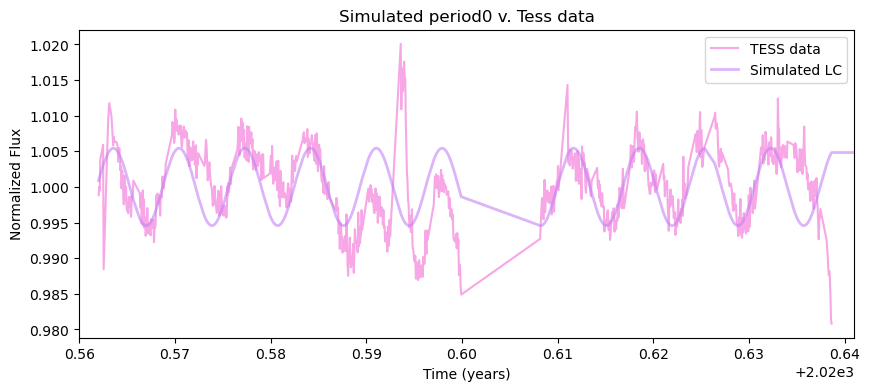

In [75]:
#Plotting a simulated LC
x_vals = data_all.index
    #choosing the best period 
period0 = p1 /365.25

#creating a sin function for the simulated LC
    #amplitude...
amp0 = 1 / 120 * primary#to get the sin function between 1.02 and 0.98?
    #omega
omega0 = (2 * np.pi) / period0 
    #vertical shift
vShift0 = 1
    #horiziontal shift???
hShift0 = -0.95
#actual function!
sim0 = amp0 * np.sin(omega0 * x_vals + hShift0) + vShift0 

#plotting 
fig, ax = plt.subplots(1,1, figsize=(10,4)) 
ax.plot(data0_normed.index[indx_outofeclipse0], data0_normed['flux'].iloc[indx_outofeclipse0], c="#f7a7e5", label='TESS data')
ax.plot(x_vals, sim0, c="#c682f4", label='Simulated LC', linewidth='2', alpha=0.6)
plt.ylabel("Normalized Flux")
plt.xlabel("Time (years)")
ax.set_title("Simulated period0 v. Tess data")
ax.set_xlim(2020.56, 2020.641)
plt.legend(loc='best')
plt.show()

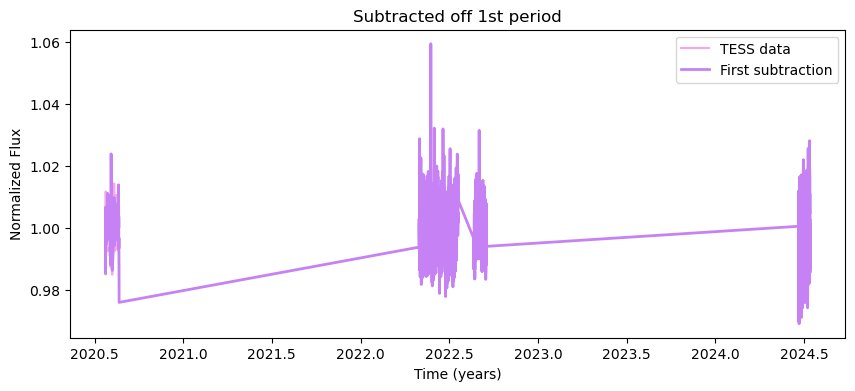

In [76]:
#subtracting off the simulated LC
    #subtracted flux
subtracted0 = data_all['flux'] - sim0
    #subtracting off from error??
error0 = data_all['flux_err'] - sim0

#putting into a new df 
sub0_stuff = {
    'flux' : subtracted0, 
    'flux_err' : error0, 
    'time' : x_vals
}
sub0 = pd.DataFrame(sub0_stuff)

#plotting the whole thing
fig, ax = plt.subplots(1,1, figsize=(10,4))
ax.plot(data0_normed.index[indx_outofeclipse0], data0_normed['flux'].iloc[indx_outofeclipse0], c="#f7a7e5", label='TESS data')
ax.plot(sub0['time'], sub0['flux'] + 1.00, c="#c682f4", label='First subtraction', linewidth='2')
plt.ylabel("Normalized Flux")
plt.xlabel("Time (years)")
ax.set_title("Subtracted off 1st period")
plt.legend(loc='best')
plt.show()

[1.67220736 1.67780753 1.65289775]
  Top 3 periods (in days) =  1.6722073578595318 1.677807531493077 1.6528977530058546
  (their powers were:  [0.52959578 0.47134372 0.44134393]


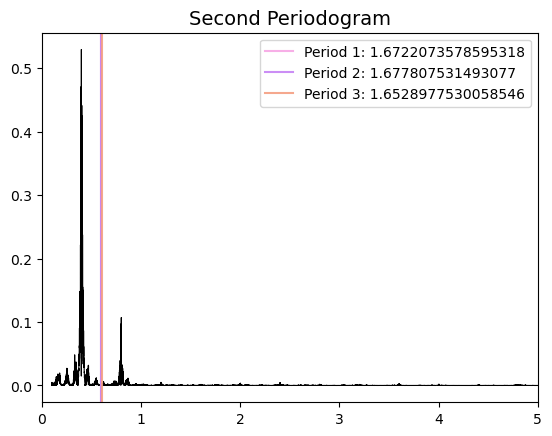

In [77]:
#Second Periodogram
possiblef = np.linspace(0.1, 30, 50000)
power = LombScargle(sub0.index.values*365.25,sub0['flux'].values).power(possiblef)
frequency = possiblef

indx_sorted = (-power).argsort()
print(period[indx_sorted[0:3]])
p11, p22, p33 = period[indx_sorted[0:3]] #period but in days??
print("  Top 3 periods (in days) = ",p11, p22, p33) 
print("  (their powers were: ",power[indx_sorted[0:3]])

fig, ax = plt.subplots()
ax.plot(frequency, power, c='black', linewidth = '0.8')
ax.axvline(x=1/p11, color='#f7a7e5', linestyle='-', label=f'Period 1: {p11}', alpha=0.9)
ax.axvline(x=1/p22, color='#c682f4', linestyle='-', label=f'Period 2: {p22}', alpha=0.9)
ax.axvline(x=1/p33, color="#f49f82", linestyle='-', label=f'Period 3: {p33}', alpha=0.9)
ax.set_title('Second Periodogram', fontsize=14)
ax.set_xlim(0,5) #goes to 25, but it's a flat line so I'm zooming in!
ax.legend()
plt.show()

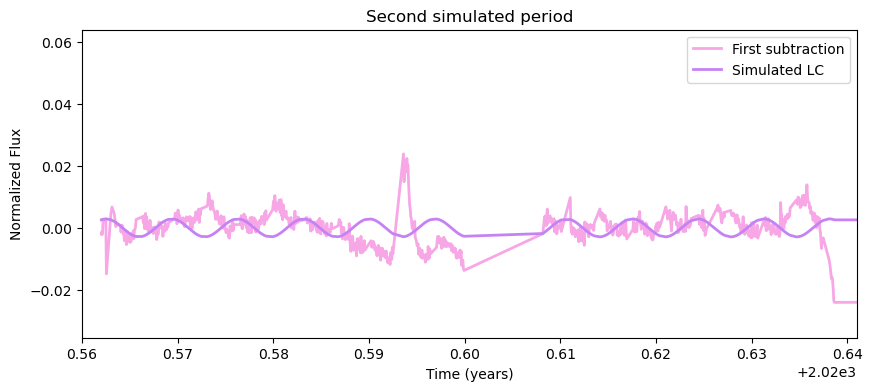

In [78]:
#Plotting a second simulated LC
    #choosing the best period 
period1 = p11 / 365.25

#creating a sin function for the simulated LC
    #amplitude...
amp1 = 1 / 120 * secondary #to get the sin function between 1.02 and 0.98?
    #omega
omega1 = (2 * np.pi) / period0 
    #vertical shift
vShift1 = 1
    #horiziontal shift???
hShift1 = 0
#actual function!
sim1 = amp1 * np.sin(omega1 * x_vals +hShift1) + vShift1 

#plotting 
fig, ax = plt.subplots(1,1, figsize=(10,4)) 
#ax.plot(data0_normed.index[indx_outofeclipse0], data0_normed['flux'].iloc[indx_outofeclipse0], c="#f7a7e5", label='TESS data')
ax.plot(sub0['time'], sub0['flux'], c="#f7a7e5", label='First subtraction', linewidth='2')
ax.plot(x_vals, sim1-1, c="#c682f4", label='Simulated LC', linewidth='2') #subtracted by one to make them line up?
plt.ylabel("Normalized Flux")
plt.xlabel("Time (years)")
ax.set_title("Second simulated period")
ax.set_xlim(2020.56, 2020.641)
plt.legend(loc='best')
plt.show()

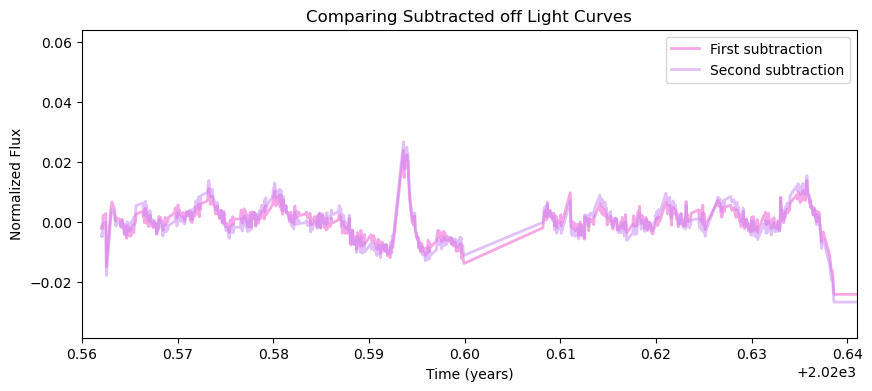

In [79]:
#subtracting off the simulated LC
    #subtracted flux
subtracted1 = sub0['flux'] - sim1
    #subtracting off from error??
error1 = sub0['flux_err'] - sim1

#putting into a new df 
sub1_stuff = {
    'flux' : subtracted1, 
    'flux_err' : error1, 
    'time' : x_vals
}
sub1 = pd.DataFrame(sub1_stuff)

#plotting
fig, ax = plt.subplots(1,1, figsize=(10,4))
ax.plot(sub0['time'], sub0['flux'], c="#f7a7e5", label='First subtraction', linewidth='2')
ax.plot(sub1['time'], sub1['flux']+1, c="#c682f4", label='Second subtraction', linewidth='2', alpha=0.5)
plt.ylabel("Normalized Flux")
plt.xlabel("Time (years)")
ax.set_title("Comparing Subtracted off Light Curves")
ax.set_xlim(2020.56, 2020.641)
plt.legend()
plt.show()

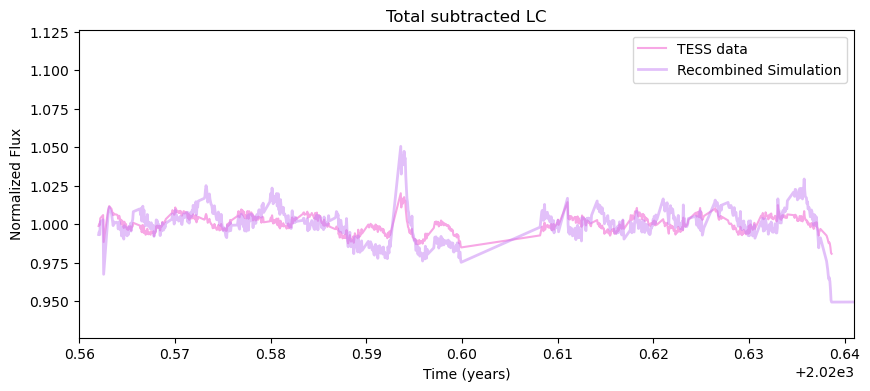

In [80]:
#Adding the subtracted sections together
simTotal = sub1['flux'] + sub0['flux']

fig, ax = plt.subplots(1,1, figsize=(10,4))
ax.plot(data0_normed.index[indx_outofeclipse0], data0_normed['flux'].iloc[indx_outofeclipse0], c="#f7a7e5", label='TESS data')
ax.plot(sub1['time'], simTotal+2, c="#c682f4", label='Recombined Simulation', linewidth='2',alpha=0.5)
plt.ylabel("Normalized Flux")
plt.xlabel("Time (years)")
ax.set_title("Total subtracted LC")
ax.set_xlim(2020.56, 2020.641)
plt.legend()
plt.show()

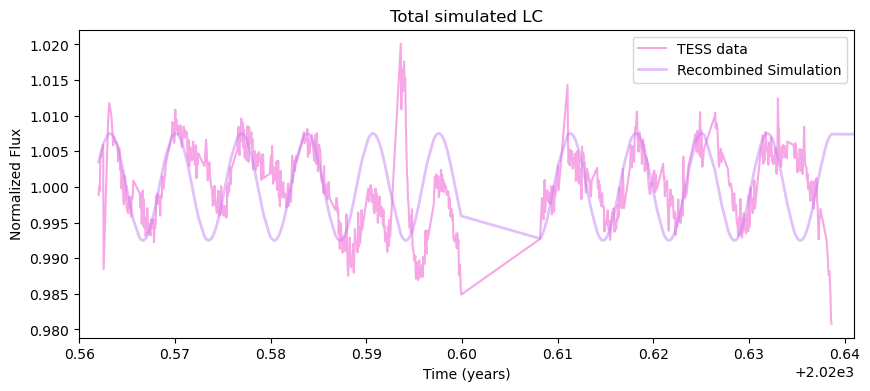

In [81]:
#Plotting the total subtracted light curve 
simTotal = sim1 + sim0 -1

fig, ax = plt.subplots(1,1, figsize=(10,4))
ax.plot(data0_normed.index[indx_outofeclipse0], data0_normed['flux'].iloc[indx_outofeclipse0], c="#f7a7e5", label='TESS data')
ax.plot(sub1['time'], simTotal, c="#c682f4", label='Recombined Simulation', linewidth='2',alpha=0.5)
plt.ylabel("Normalized Flux")
plt.xlabel("Time (years)")
ax.set_title("Total simulated LC")
ax.set_xlim(2020.56, 2020.641)
plt.legend(loc='best')
plt.show()

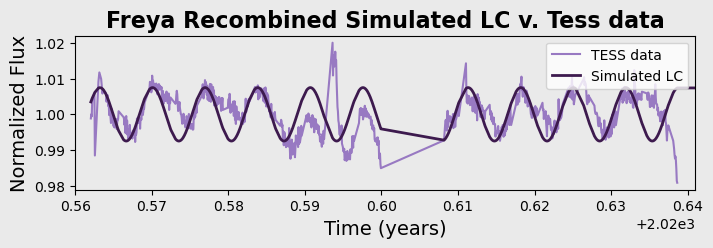

In [82]:
#finalized visualization
fig, ax = plt.subplots(1,1, figsize=(8,2)) 
ax.plot(data0_normed.index[indx_outofeclipse0], data0_normed['flux'].iloc[indx_outofeclipse0], c="#9879C2", label='TESS data')
ax.plot(x_vals, simTotal, c="#3D1A4E", label='Simulated LC', linewidth='2')
plt.ylabel("Normalized Flux", fontsize='14')
plt.xlabel("Time (years)", fontsize='14')
ax.set_title("Freya Recombined Simulated LC v. Tess data", fontsize='16', fontweight='bold')
ax.set_xlim(2020.56, 2020.641)
fig.set_facecolor('#EAEAEA')
ax.set_facecolor('#EAEAEA')
plt.legend(loc='upper right')
plt.show()

In [83]:
print(f"Rotation Period of Star 1 {p1}.")
print(f"Rotation Period of Star 2 {p11}.")

Rotation Period of Star 1 2.5099899598393574.
Rotation Period of Star 2 1.6722073578595318.
